In [1]:
# Import Dependencies
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as dsets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable
from torch.utils.data import DataLoader, TensorDataset
from math import floor 
import torch.nn.functional as F
# Check if MPS is available, otherwise fall back to CPU

# Check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = torch.device("mps" if torch.backends.mps.is_available() else device1)print(f"Using device: {device1}")
print(f"Using device: {device}")
from sklearn.metrics import confusion_matrix  # Add this import


Using device: cuda


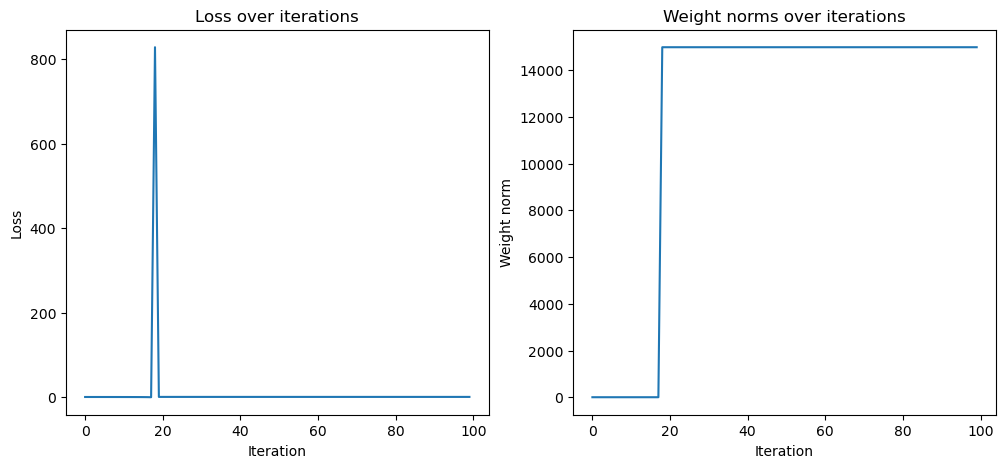

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define the network
class SimpleNetwork(nn.Module):
    def __init__(self, input_size):
        super(SimpleNetwork, self).__init__()
        self.w_e = nn.Parameter(torch.randn(input_size))
        self.w_i = nn.Parameter(torch.randn(input_size))
        self.e_to_i_ratio = 10.0  # Example value, can be adjusted
    
    def forward(self, x_e, x_i):
        excitatory_input = torch.sum(self.w_e * x_e)
        inhibitory_input = torch.sum(self.w_i * x_i)
        output = excitatory_input / (excitatory_input + self.e_to_i_ratio * inhibitory_input + 1)
        return output

# Define the loss function (squared error for simplicity)
def loss_function(output, target):
    return (output - target) ** 2

# Simulation parameters
input_size = 10
learning_rate = 0.01
num_iterations = 100

# Initialize network and optimizer
network = SimpleNetwork(input_size)
optimizer = optim.SGD(network.parameters(), lr=learning_rate)

# Generate some random inputs and target
x_e = torch.randn(input_size)
x_i = torch.randn(input_size)
target = torch.tensor(1.0)  # Example target

# Lists to store metrics
losses = []
weight_norms = []

# Training loop
for iteration in range(num_iterations):
    optimizer.zero_grad()
    output = network(x_e, x_i)
    loss = loss_function(output, target)
    loss.backward()
    optimizer.step()
    
    # Store metrics
    losses.append(loss.item())
    weight_norms.append(torch.norm(network.w_e).item() + torch.norm(network.w_i).item())

# Plotting the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(losses)
plt.title("Loss over iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(weight_norms)
plt.title("Weight norms over iterations")
plt.xlabel("Iteration")
plt.ylabel("Weight norm")

plt.show()
# import wandb

# # Initialize W&B
# wandb.init(project="vanishing-gradient-check", config={
#     "learning_rate": lr,
#     "epochs": num_epochs,
#     "batch_size": batch_size,
#     "architecture": "Dendritic_Network"
# })

# # Configure logging
# wandb.config.update({"layers": dendrite_layers_n, "units_per_layer": dendrite_branch_n})

In [3]:
# Function to plot an image with the scale color bar
def plotWithColor(data, title=''):
    if torch.is_tensor(data):
        data = data.cpu().numpy()
    ax = plt.subplot()
    im = ax.imshow(data)
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    plt.colorbar(im, cax=cax)
    if len(title) > 0:
        plt.title(title)
    plt.show()

In [4]:


# Downloading MNIST data
train_data = dsets.MNIST(root='./data', train=True, transform=transforms.ToTensor(), download=True)
test_data = dsets.MNIST(root='./data', train=False, transform=transforms.ToTensor())

# Compute mean images for each label in training data
def compute_label_means(dataset):
    label_means = {}
    for image, label in dataset:
        if label not in label_means:
            label_means[label] = []
        label_means[label].append(image)
    for label in label_means:
        label_means[label] = torch.mean(torch.stack(label_means[label]), dim=0)
    return label_means

# Create new image set N for train and test data
label_means_train = compute_label_means(train_data)
label_means_test = compute_label_means(test_data)

def create_images_n(dataset, label_means):
    images_n = []
    for image, label in dataset:
        mean_image = label_means[label]
        images_n.append(image - 0 * mean_image)
    return images_n

images_n_train = create_images_n(train_data, label_means_train)
images_n_test = create_images_n(test_data, label_means_test)

# %%
# Loading the data
batch_size = 500  # the size of input data taken for one iteration
train_gen = torch.utils.data.DataLoader(dataset=train_data, batch_size=batch_size, shuffle=True)
test_gen = torch.utils.data.DataLoader(dataset=test_data, batch_size=batch_size, shuffle=False)



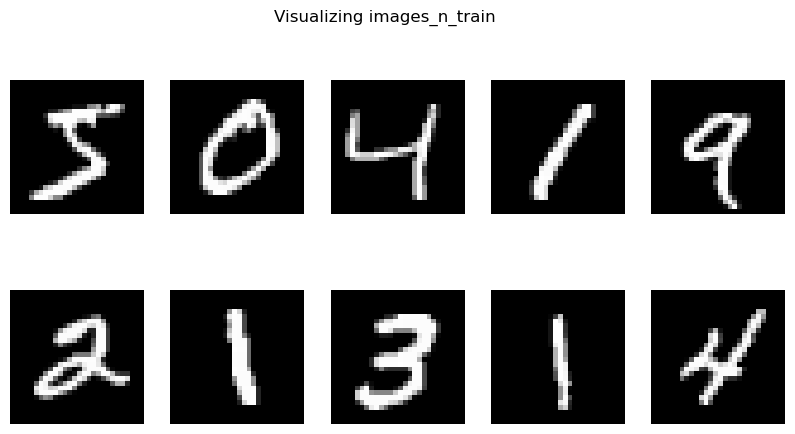

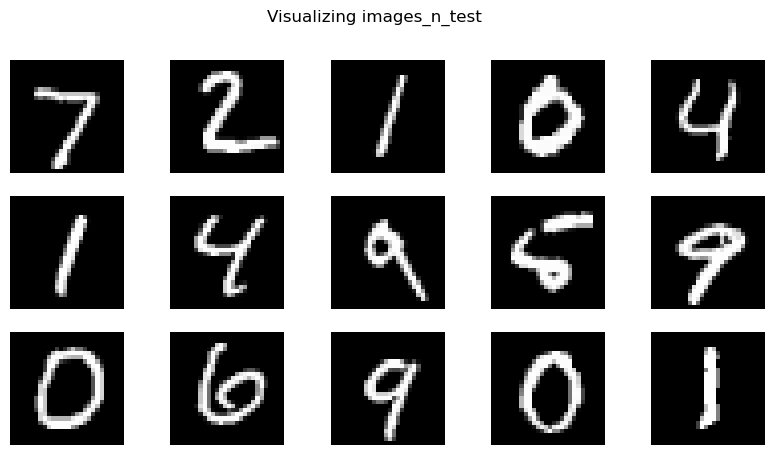

In [5]:
import matplotlib.pyplot as plt

# Function to plot a grid of images
def plot_images(images, n_rows=2, n_cols=5, title=''):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 5))
    fig.suptitle(title)
    for i in range(n_rows * n_cols):
        if i < len(images):
            image = images[i].squeeze().numpy()  # Convert to numpy and remove channel dimension
            ax = axes[i // n_cols, i % n_cols]
            ax.imshow(image, cmap='gray')
            ax.axis('off')
    plt.show()

# Visualize the first 10 images in the training set
plot_images(images_n_train[:10], title='Visualizing images_n_train')

plot_images(images_n_test[:15], n_rows=3, n_cols=5, title='Visualizing images_n_test')

In [6]:
# Define Hyperparameters
use_transformed_input = False


input_size = 2 * 784  # img_size = (28,28) ---> 28*28=784 in total x 2 for side by side images
num_classes = 10  # number of output classes, discrete range [0,9]
num_epochs = 50  # number of times which the entire dataset is passed through the model
lr = 1e-2  # learning rate

# Define Dendrite Hyperparameters
excitatory_synapses_per_dendrite_branch = 50
inhibitory_synapses_per_dendrite_branch = 1
dendrite_layers_n = 5#2
dendrite_branch_per_dendrite = [4, 4, 4, 4, 4]#[3, 3]  #[4, 4, 4, 4, 4]# list with one fewer entries than dendrite_layers_n
dendrite_per_soma = 10
e_to_i_ratio = excitatory_synapses_per_dendrite_branch / inhibitory_synapses_per_dendrite_branch
soma_n = num_classes
synapses_per_inhibitory_unit = 200
inhibitory_units_n = 100#1
sigmoid_offset = 5
dendrite_branch_n = [None] * dendrite_layers_n
dendrite_branch_n[0] = dendrite_per_soma * soma_n

for i in range(1, dendrite_layers_n):
    dendrite_branch_n[i] = dendrite_branch_n[i - 1] * dendrite_branch_per_dendrite[i - 1]

shunting = True

print(dendrite_branch_n)
sum(dendrite_branch_n)

[100, 400, 1600, 6400, 25600]


34100

In [7]:
# Define batch_size
# Index arrays
index_list1 = torch.tensor(range(batch_size))
index_list2 = torch.tensor(list(range(1, batch_size)) + [0])
modulo_base = num_classes

def sum_labels(labels_in):
    return torch.remainder(labels_in[index_list1] + labels_in[index_list2], modulo_base)

def transform_images(images_in):
    return torch.cat((images_in[index_list1, :], images_in[index_list2, :]), 1)

# Modified function to transform images for inhibitory input
def transform_images_inh(images_m, images_n):
    return torch.cat((images_m[index_list1, :], images_n[index_list2, :]), 1)

In [8]:
# %%
# Define layer class that only keeps K top weights
class TopKLinear(nn.Linear):
    """ Custom Linear layer that only uses the strongest K weights """
    def __init__(self, in_features, out_features, keep_in_features, bias=False):
        super().__init__(in_features, out_features, bias=bias)
        self.keep_in_features = keep_in_features
        self.topk_indices = []
        self.mask = 0 * self.weight.data
        self.net_weight = 0 * self.weight.data

    def forward(self, x):
        self.mask = 0 * self.weight.data
        self.topk_indices = torch.topk(self.weight, self.keep_in_features, 1, largest=True)[1]
        self.mask[torch.arange(self.weight.shape[0])[:, None], self.topk_indices] = 1
        self.net_weight = self.mask * self.weight
        w_times_x = torch.mm(x, self.net_weight.t())
        return w_times_x

In [9]:
# Define layer class that uses a block structure
class BlockLinear(nn.Linear):
    """ Custom Linear layer that uses block structures """
    def __init__(self, in_features, out_features, bias=False):
        super().__init__(in_features, out_features, bias=bias)
        block_size = floor(in_features / out_features)
        assert(block_size * out_features == in_features)
        self.block_size = block_size
        self.mask = torch.zeros(out_features, in_features, device=device)
        for counter in range(self.out_features):
            self.mask[counter, torch.arange(counter * self.block_size, (1 + counter) * self.block_size)] = 1

    def forward(self, x):
        self.net_weight = self.weight * self.mask
        w_times_x = torch.mm(x, self.net_weight.t())
        return w_times_x

In [10]:
####Define dendrite branch layer
# class DendriteBranchLayer(nn.Module):
#     """ Dendrite Branch Layer """
#     def __init__(self, inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch,
#                  excitatory_synapses_per_dendrite_branch, shunting=False, branch_input=False, input_dendrite_branch_n=None):
#         super(DendriteBranchLayer, self).__init__()
#         self.branch_input = branch_input
#         self.shunting = shunting
#         self.inputs_to_dendrite_branch = TopKLinear(input_size, dendrite_branch_n, excitatory_synapses_per_dendrite_branch)
#         self.inhibition_to_dendrite_branch = TopKLinear(inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch)

#         if self.branch_input:
#             self.dendrite_branch_inputs_to_dendrite_branch = BlockLinear(input_dendrite_branch_n, dendrite_branch_n)
#             self.dendrite_branch_inputs_to_dendrite_branch.requires_grad_(False)  # we don't train this.  All dendrites have the same weight

#         self.sigmoid = nn.Sigmoid()

#     def forward(self, input, inhibition_outputs, dendrite_branch_outputs=None):
#         self.dendrite_inhibition = self.inhibition_to_dendrite_branch(inhibition_outputs)
#         self.dendrite_excitation = self.inputs_to_dendrite_branch(input)

#         if self.branch_input:
#             self.dendrite_depolarization = self.dendrite_branch_inputs_to_dendrite_branch(dendrite_branch_outputs)
#             total_excitatory_input = self.dendrite_excitation + self.dendrite_depolarization
#         else:
#             total_excitatory_input = self.dendrite_excitation

#         if self.shunting:
#             self.dendrite_act = total_excitatory_input / (total_excitatory_input + e_to_i_ratio * self.dendrite_inhibition + 1)
#             self.dendrite_out = self.dendrite_act
#         else:
#             self.dendrite_act = total_excitatory_input - e_to_i_ratio * self.dendrite_inhibition - 3
#             #self.dendrite_out = self.sigmoid(self.dendrite_act)
#             self.dendrite_out = F.leaky_relu(self.dendrite_act)

#         return self.dendrite_out

####### with batch norm:
class DendriteBranchLayer(nn.Module):
    def __init__(self, inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch,
                 excitatory_synapses_per_dendrite_branch, shunting=False, branch_input=False, input_dendrite_branch_n=None):
        super(DendriteBranchLayer, self).__init__()

        self.branch_input = branch_input
        self.shunting = shunting

        self.inputs_to_dendrite_branch = TopKLinear(input_size, dendrite_branch_n, excitatory_synapses_per_dendrite_branch)
        self.inhibition_to_dendrite_branch = TopKLinear(inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch)

        if self.branch_input:
            self.dendrite_branch_inputs_to_dendrite_branch = BlockLinear(input_dendrite_branch_n, dendrite_branch_n)
            self.dendrite_branch_inputs_to_dendrite_branch.requires_grad_(False)  # we don't train this.  All dendrites have the same weight

        # Batch normalization layer
        #self.batch_norm = nn.BatchNorm1d(dendrite_branch_n, affine=False)
        self.batch_norm = nn.BatchNorm1d(dendrite_branch_n)

    def forward(self, input, inhibition_outputs, dendrite_branch_outputs=None):
        self.dendrite_inhibition = self.inhibition_to_dendrite_branch(inhibition_outputs)
        self.dendrite_excitation = self.inputs_to_dendrite_branch(input)

        if self.branch_input:
            self.dendrite_depolarization = self.dendrite_branch_inputs_to_dendrite_branch(dendrite_branch_outputs)
            total_excitatory_input = self.dendrite_excitation + self.dendrite_depolarization
        else:
            total_excitatory_input = self.dendrite_excitation

        if self.shunting:
            self.dendrite_act = total_excitatory_input / (total_excitatory_input + e_to_i_ratio * self.dendrite_inhibition + 1)
        else:
            self.dendrite_act = total_excitatory_input - e_to_i_ratio * self.dendrite_inhibition - 3

        # Apply batch normalization before activation function
        self.dendrite_act = self.batch_norm(self.dendrite_act)

        # Apply activation function (e.g., LeakyReLU)
        #self.dendrite_out = F.leaky_relu(self.dendrite_act)
        self.dendrite_out = torch.sigmoid(self.dendrite_act)

        return self.dendrite_out

In [11]:
# Define dendrite branch layer with lateral and recurrent connections
class DendriteBranchLayerWithConnections(nn.Module):
    def __init__(self, inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch,
                 excitatory_synapses_per_dendrite_branch, shunting=False, branch_input=False, input_dendrite_branch_n=None):
        super(DendriteBranchLayerWithConnections, self).__init__()

        self.branch_input = branch_input
        self.shunting = shunting
        self.dendrite_branch_n = dendrite_branch_n

        self.inputs_to_dendrite_branch = TopKLinear(input_size, dendrite_branch_n, excitatory_synapses_per_dendrite_branch)
        self.inhibition_to_dendrite_branch = TopKLinear(inhibitory_units_n, dendrite_branch_n, inhibitory_synapses_per_dendrite_branch)

        # Lateral connections
        self.lateral_weights = nn.Parameter(torch.randn(dendrite_branch_n, dendrite_branch_n))

        if self.branch_input:
            self.dendrite_branch_inputs_to_dendrite_branch = BlockLinear(input_dendrite_branch_n, dendrite_branch_n)
            self.dendrite_branch_inputs_to_dendrite_branch.requires_grad_(False)  # we don't train this.  All dendrites have the same weight

        self.activation = nn.ReLU()

    def forward(self, input, inhibition_outputs, dendrite_branch_outputs=None, lateral_input=None):
        self.dendrite_inhibition = self.inhibition_to_dendrite_branch(inhibition_outputs)
        self.dendrite_excitation = self.inputs_to_dendrite_branch(input)

        if self.branch_input:
            self.dendrite_depolarization = self.dendrite_branch_inputs_to_dendrite_branch(dendrite_branch_outputs)
            total_excitatory_input = self.dendrite_excitation + self.dendrite_depolarization
        else:
            total_excitatory_input = self.dendrite_excitation

        if lateral_input is not None:
            # Ensure lateral_input has the correct shape
            if lateral_input.shape[1] != self.dendrite_branch_n:
                lateral_input = lateral_input[:, :self.dendrite_branch_n]
            lateral_effect = torch.matmul(lateral_input, self.lateral_weights)
            total_excitatory_input += lateral_effect

        if self.shunting:
            self.dendrite_act = total_excitatory_input / (total_excitatory_input + e_to_i_ratio * self.dendrite_inhibition + 1)
        else:
            self.dendrite_act = total_excitatory_input - e_to_i_ratio * self.dendrite_inhibition - 3

        self.dendrite_out = self.activation(self.dendrite_act)

        return self.dendrite_out

In [12]:
#@title Define network structure
# Define network structure
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        # Inhibitory cell layer
        self.inputs_to_inhibition = TopKLinear(input_size, inhibitory_units_n, synapses_per_inhibitory_unit)

        # Dendrite layers
        self.dendrite_layers = nn.ModuleList([None] * dendrite_layers_n)
        for i in range(dendrite_layers_n - 1, -1, -1):
            is_outermost_layer = (i == (dendrite_layers_n - 1))
            branch_input = False if is_outermost_layer else True
            input_dendrite_branch_n = None if is_outermost_layer else dendrite_branch_n[i + 1]
            self.dendrite_layers[i] = DendriteBranchLayer(inhibitory_units_n, dendrite_branch_n[i], inhibitory_synapses_per_dendrite_branch,
                                                          excitatory_synapses_per_dendrite_branch, shunting,
                                                          branch_input, input_dendrite_branch_n)

        # Soma
        self.dendrite_to_soma = BlockLinear(dendrite_branch_n[0], soma_n)
        self.dendrite_to_soma.requires_grad_(False)  # We don't train this. All dendrites have the same weight

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def initWeights(self):
        with torch.no_grad():
            self.inputs_to_inhibition.weight.data = torch.sign(self.inputs_to_inhibition.weight) * self.inputs_to_inhibition.weight
            for i in range(dendrite_layers_n - 1, -1, -1):
                self.dendrite_layers[i].inputs_to_dendrite_branch.weight.data = torch.sign(self.dendrite_layers[i].inputs_to_dendrite_branch.weight) * self.dendrite_layers[i].inputs_to_dendrite_branch.weight
                self.dendrite_layers[i].inhibition_to_dendrite_branch.weight.data = torch.sign(self.dendrite_layers[i].inhibition_to_dendrite_branch.weight) * self.dendrite_layers[i].inhibition_to_dendrite_branch.weight
                if i < (dendrite_layers_n - 1):
                    self.dendrite_layers[i].dendrite_branch_inputs_to_dendrite_branch.weight.data = 1.0 * self.dendrite_layers[i].dendrite_branch_inputs_to_dendrite_branch.mask

            self.dendrite_to_soma.weight.data = 1.0 * self.dendrite_to_soma.mask

    def trimWeights(self):
        with torch.no_grad():
            self.inputs_to_inhibition.weight.data = torch.maximum(self.inputs_to_inhibition.weight, 0 * self.inputs_to_inhibition.weight)
            for i in range(dendrite_layers_n - 1, -1, -1):
                self.dendrite_layers[i].inputs_to_dendrite_branch.weight.data = torch.maximum(self.dendrite_layers[i].inputs_to_dendrite_branch.weight, 0 * self.dendrite_layers[i].inputs_to_dendrite_branch.weight)
                self.dendrite_layers[i].inhibition_to_dendrite_branch.weight.data = torch.maximum(self.dendrite_layers[i].inhibition_to_dendrite_branch.weight, 0 * self.dendrite_layers[i].inhibition_to_dendrite_branch.weight)

    def forward(self, input):
        self.inhibition_act = self.inputs_to_inhibition(input)
        if shunting:
            self.inhibition_out = self.inhibition_act / (1 + self.inhibition_act)
        else:
            self.inhibition_out = self.sigmoid(self.inhibition_act - sigmoid_offset)

        self.dendrite_branch_out = [None] * dendrite_layers_n

        for i in range(dendrite_layers_n - 1, -1, -1):
            is_outermost_layer = (i == (dendrite_layers_n - 1))
            this_dendrite_branch_out = None if is_outermost_layer else self.dendrite_branch_out[i + 1]
            self.dendrite_branch_out[i] = self.dendrite_layers[i](input, self.inhibition_out, this_dendrite_branch_out)

        self.soma_act = self.dendrite_to_soma(self.dendrite_branch_out[0])
        # self.soma_out = self.sigmoid(self.soma_act - sigmoid_offset)

        return self.soma_act

In [13]:
class NetWithConnections(nn.Module):
    def __init__(self):
        super(NetWithConnections, self).__init__()

        # Inhibitory cell layer
        self.inputs_to_inhibition = TopKLinear(input_size, inhibitory_units_n, synapses_per_inhibitory_unit)

        # Dendrite layers with connections
        self.dendrite_layers = nn.ModuleList([None] * dendrite_layers_n)
        for i in range(dendrite_layers_n - 1, -1, -1):
            is_outermost_layer = (i == (dendrite_layers_n - 1))
            branch_input = False if is_outermost_layer else True
            input_dendrite_branch_n = None if is_outermost_layer else dendrite_branch_n[i + 1]
            self.dendrite_layers[i] = DendriteBranchLayerWithConnections(
                inhibitory_units_n, dendrite_branch_n[i], inhibitory_synapses_per_dendrite_branch,
                excitatory_synapses_per_dendrite_branch, shunting,
                branch_input, input_dendrite_branch_n)

        # Soma
        self.dendrite_to_soma = BlockLinear(dendrite_branch_n[0], soma_n)
        self.dendrite_to_soma.requires_grad_(False)

        self.activation = nn.ReLU()

    def initWeights(self):
        with torch.no_grad():
            self.inputs_to_inhibition.weight.data = torch.sign(self.inputs_to_inhibition.weight) * self.inputs_to_inhibition.weight
            for i in range(dendrite_layers_n - 1, -1, -1):
                self.dendrite_layers[i].inputs_to_dendrite_branch.weight.data = torch.sign(self.dendrite_layers[i].inputs_to_dendrite_branch.weight) * self.dendrite_layers[i].inputs_to_dendrite_branch.weight
                self.dendrite_layers[i].inhibition_to_dendrite_branch.weight.data = torch.sign(self.dendrite_layers[i].inhibition_to_dendrite_branch.weight) * self.dendrite_layers[i].inhibition_to_dendrite_branch.weight
                if i < (dendrite_layers_n - 1):
                    self.dendrite_layers[i].dendrite_branch_inputs_to_dendrite_branch.weight.data = 1.0 * self.dendrite_layers[i].dendrite_branch_inputs_to_dendrite_branch.mask

            self.dendrite_to_soma.weight.data = 1.0 * self.dendrite_to_soma.mask

    def trimWeights(self):
        with torch.no_grad():
            self.inputs_to_inhibition.weight.data = torch.maximum(self.inputs_to_inhibition.weight, 0 * self.inputs_to_inhibition.weight)
            for i in range(dendrite_layers_n - 1, -1, -1):
                self.dendrite_layers[i].inputs_to_dendrite_branch.weight.data = torch.maximum(self.dendrite_layers[i].inputs_to_dendrite_branch.weight, 0 * self.dendrite_layers[i].inputs_to_dendrite_branch.weight)
                self.dendrite_layers[i].inhibition_to_dendrite_branch.weight.data = torch.maximum(self.dendrite_layers[i].inhibition_to_dendrite_branch.weight, 0 * self.dendrite_layers[i].inhibition_to_dendrite_branch.weight)

    def forward(self, input):
        self.inhibition_act = self.inputs_to_inhibition(input)
        self.inhibition_out = self.activation(self.inhibition_act - sigmoid_offset)

        self.dendrite_branch_out = [None] * dendrite_layers_n
        lateral_input = None

        for i in range(dendrite_layers_n - 1, -1, -1):
            is_outermost_layer = (i == (dendrite_layers_n - 1))
            this_dendrite_branch_out = None if is_outermost_layer else self.dendrite_branch_out[i + 1]

            self.dendrite_branch_out[i] = self.dendrite_layers[i](
                input, self.inhibition_out, this_dendrite_branch_out, lateral_input)

            lateral_input = self.dendrite_branch_out[i]

        self.soma_act = self.dendrite_to_soma(self.dendrite_branch_out[0])
        return self.soma_act

In [14]:
# Build the model
use_new_input_for_inhibition = use_transformed_input  # Toggle between the new and original input for the inhibitory network

#net = NetWithConnections().to(device)
net = Net().to(device)
net.initWeights()

In [15]:
# #@title Save the initial parameters in paramList

# paramList=[]
# for name, param in net.named_parameters():
#     if param.requires_grad:
#       print(name)
#       with torch.no_grad():
#         paramList.append([name, param.data.detach().cpu()])
# paramList.append(["net.inputs_to_dendrites.topk_indices", net.inputs_to_dendrites.topk_indices.data.detach().cpu()])
# paramList.append(["net.inputs_to_dendrites.net_weight", net.inputs_to_dendrites.net_weight.data.detach().cpu()])
# paramList.append(["net.inhibition_to_dendrites.topk_indices", net.inhibition_to_dendrites.topk_indices.data.detach().cpu()])
# paramList.append(["net.inhibition_to_dendrites.net_weight", net.inhibition_to_dendrites.net_weight.data.detach().cpu()])

In [16]:
# Define loss-function & optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)
#optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.98)
lossi = []

print(f"Learning rate: {lr}")

Learning rate: 0.01


In [17]:
# Training the model
# for epoch in range(3 * num_epochs):
#     for i, (images_raw, labels_raw) in enumerate(train_gen):
#         images = transform_images(images_raw.view(-1, 28*28)).to(device)
#         labels = sum_labels(labels_raw).to(device)

#         optimizer.zero_grad()
#         outputs = net(images)
#         loss = loss_function(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         net.trimWeights()
#         lossi.append(loss.item())

#         if (i + 1) % 100 == 0:
#             scheduler.step()
#             print('Epoch [%d/%d], Step [%d/%d], Loss: %.4f'
#                   % (epoch + 1, num_epochs, i + 1, len(train_data) // batch_size, loss.data))
            
# Calculate the mean image for each label
# Calculate the mean image for each label
# Calculate the mean image for each label
mean_images = []
for label in range(num_classes):
    label_images = []
    for images_raw, labels_raw in train_gen:
        mask = labels_raw == label
        if mask.any():
            label_images.append(images_raw[mask].view(mask.sum(), -1))
    if label_images:
        label_images = torch.cat(label_images, 0)
        mean_image = label_images.mean(dim=0)
    else:
        mean_image = torch.zeros(28*28)  # Fallback if no images for this label (unlikely)
    mean_images.append(mean_image)

mean_images = torch.stack(mean_images)

# Ensure mean_images is moved to the correct device
mean_images = mean_images.to(device)

# Initialize lists to track metrics
# Training the model
grad_norms = []
weight_norms = []
losses = []

# Training the model
for epoch in range(num_epochs):
    for i, (images_raw, labels_raw) in enumerate(train_gen):
        images = images_raw.view(-1, 28*28).to(device)
        labels = sum_labels(labels_raw).to(device)

        optimizer.zero_grad()
        if use_new_input_for_inhibition:
            # Compute new input for inhibition using N
            images_n = images - mean_images[labels_raw]
            # Transform images N and M similarly to keep input size consistent
            inhibition_input = transform_images(images_n.view(-1, 28*28)).to(device)
            excitatory_input = transform_images(images.view(-1, 28*28)).to(device)
        else:
            # Use the same input for both inhibitory and excitatory pathways
            excitatory_input = transform_images(images.view(-1, 28*28)).to(device)
            inhibition_input = excitatory_input

        # Forward pass through the network
        outputs = net(excitatory_input)
        loss = loss_function(outputs, labels)
        loss.backward()

        optimizer.step()
        net.trimWeights()

        if (i + 1) % 100 == 0:
            scheduler.step()
            print('Epoch [%d/%d], Step [%d/%d], Loss: %.4f'
                  % (epoch + 1, num_epochs, i + 1, len(train_data) // batch_size, loss.item()))

Epoch [1/50], Step [100/120], Loss: 1.9035
Epoch [2/50], Step [100/120], Loss: 1.4968
Epoch [3/50], Step [100/120], Loss: 1.1266
Epoch [4/50], Step [100/120], Loss: 1.0018
Epoch [5/50], Step [100/120], Loss: 0.9345
Epoch [6/50], Step [100/120], Loss: 0.8774
Epoch [7/50], Step [100/120], Loss: 0.9590
Epoch [8/50], Step [100/120], Loss: 0.8915
Epoch [9/50], Step [100/120], Loss: 0.7478
Epoch [10/50], Step [100/120], Loss: 0.7738
Epoch [11/50], Step [100/120], Loss: 0.7140
Epoch [12/50], Step [100/120], Loss: 0.7809
Epoch [13/50], Step [100/120], Loss: 0.8053
Epoch [14/50], Step [100/120], Loss: 0.7225
Epoch [15/50], Step [100/120], Loss: 0.6734
Epoch [16/50], Step [100/120], Loss: 0.6674
Epoch [17/50], Step [100/120], Loss: 0.6895
Epoch [18/50], Step [100/120], Loss: 0.5420
Epoch [19/50], Step [100/120], Loss: 0.6384
Epoch [20/50], Step [100/120], Loss: 0.5782
Epoch [21/50], Step [100/120], Loss: 0.6116
Epoch [22/50], Step [100/120], Loss: 0.5512
Epoch [23/50], Step [100/120], Loss: 0.56

In [18]:
# %%
# Evaluating the accuracy of the model
correct = 0
total = 0
all_preds = []
all_labels = []

for images_raw, labels_raw in test_gen:
    images = transform_images(images_raw.view(-1, 28*28)).to(device)
    labels = sum_labels(labels_raw).to(device)

    with torch.no_grad():
        output = net(images)
        _, predicted = torch.max(output, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = (100 * correct) / total
print(f'Accuracy of the model: {accuracy:.3f} %')

# Generate confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Plotting the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix\nAccuracy of the model: {accuracy:.3f} %')
plt.show()

# %%
# Plot Gradient Norms
plt.plot(grad_norms)
plt.title("Gradient Norms over Time")
plt.xlabel("Iteration")
plt.ylabel("Gradient Norm")
plt.show()

# Plot Losses
plt.plot(losses)
plt.title("Loss over Time")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# Plot Weight Norms
plt.plot(weight_norms)
plt.title("Weight Norms over Time")
plt.xlabel("Iteration")
plt.ylabel("Weight Norm")
plt.show()

Accuracy of the model: 85.210 %


NameError: name 'sns' is not defined

<Figure size 1000x800 with 0 Axes>

In [ ]:
# %%
# Visualize dendrite weights
plt.rcParams["figure.figsize"] = (20, 3)

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inputs_to_inhibition mask")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.mask.data)

# Checking for inhibition_to_dendrite_branch attribute
if hasattr(net, 'inhibition_to_dendrite_branch'):
    print("inhibition_to_dendrite_branch")
    plt.ylabel("inh unit")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

    print("inhibition_to_dendrite_branch net")
    plt.ylabel("inh unit net")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

    print("inhibition_to_dendrite_branch mask")
    plt.ylabel("inh unit mask")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())
else:
    print("Attribute 'inhibition_to_dendrite_branch' not found in 'Net' class")

# Checking for inhibition_to_dendrite attribute
if hasattr(net, 'inhibition_to_dendrite'):
    print("inhibition_to_dendrite")
    plt.ylabel("inh unit")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.weight.data.t())

    print("inhibition_to_dendrite net")
    plt.ylabel("inh unit net")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

    print("inhibition_to_dendrite mask")
    plt.ylabel("inh unit mask")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.mask.data.t())
else:
    print("Attribute 'inhibition_to_dendrite' not found in 'Net' class")

In [ ]:
# %%
# Visualize sorted labels and corresponding images
labels_sort, labels_sort_ind = torch.sort(labels)
images_sort = images[labels_sort_ind]
plt.plot(labels_sort.cpu().numpy())

images_solo = images_raw.view(-1, 28*28).to(device)
labels_solo_sort, labels_solo_sort_ind = torch.sort(labels_raw)
images_solo_sort = images_solo[labels_solo_sort_ind]
plt.plot(labels_solo_sort.cpu().numpy())

# Compute outputs for sorted images
with torch.no_grad():
    output = net(transform_images(images_solo_sort))

# %%
# Visualize various neural activities
plt.rcParams["figure.figsize"] = (20, 3)
plotWithColor(net.inhibition_act.t(), 'inhibition_act')
plotWithColor(net.inhibition_out.t(), 'inhibition_out')
plotWithColor(net.dendrite_branch_inhibition, 'dendrite_branch_inhibition')
plotWithColor(net.dendrite_branch_excitation, 'dendrite_branch_excitation')
plotWithColor(net.dendrite_branch_act, 'dendrite_branch_act')
plotWithColor(net.dendrite_branch_out, 'dendrite_branch_out')
plotWithColor(net.dendrite_inhibition.t(), 'dendrite_inhibition')
plotWithColor(net.dendrite_excitation.t(), 'dendrite_excitation')
plotWithColor(net.dendrite_depolarization.t(), 'dendrite_depolarization')
plotWithColor(net.dendrite_act.t(), 'dendrite_act')
plotWithColor(net.dendrite_out.t(), 'dendrite_out')
plotWithColor(net.soma_act.t(), 'soma_act')

In [ ]:
# %%
# The shape of the total excitatory input to each main dendrite of each soma
for soma_counter in range(soma_n):
    fig, axs = plt.subplots(1, dendrite_per_soma)
    fig.set_figwidth(20)
    for dendrite_counter in range(dendrite_per_soma):
        imAvg = 0 * net.inputs_to_dendrite_branch.net_weight.data[0, :].reshape(56, 28)
        start_dendrite_branch = soma_counter * dendrite_branch_per_soma + dendrite_counter * dendrite_branch_per_dendrite
        for counter in range(dendrite_branch_per_dendrite):
            imAvg += net.inputs_to_dendrite_branch.net_weight.data[start_dendrite_branch + counter, :].reshape(56, 28)
        axs[dendrite_counter].imshow(imAvg.cpu().numpy())
        axs[dendrite_counter].set_xlabel(dendrite_counter)
    axs[0].set_ylabel(soma_counter)

# The shape of the total excitatory input to all the dendrites of each soma
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
fig.suptitle('The shape of the total excitatory input to each soma', fontsize=16)

for soma_counter in range(soma_n):
    imAvg = 0 * net.inputs_to_dendrite_branch.net_weight.data[0, :].reshape(56, 28)
    for counter in range(soma_counter * dendrite_branch_per_soma, (soma_counter + 1) * dendrite_branch_per_soma):
        imAvg += net.inputs_to_dendrite_branch.net_weight.data[counter, :].reshape(56, 28)
    axs[soma_counter].imshow(imAvg.cpu().numpy())

# %%
# The shape of the total inhibitory input directly to the main dendrites of each soma
inhIndices = net.inhibition_to_dendrite.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
    imAvg = 0 * net.inputs_to_inhibition.weight.data[0, :].reshape(28, 56)
    for counter in range(soma_index * dendrite_per_soma, (soma_index + 1) * dendrite_per_soma):
        imAvg += net.inputs_to_inhibition.net_weight.data[inhIndices[counter], :].reshape(56, 28)
    fig.suptitle('The shape of the total inhibitory input directly onto dendrites of each soma', fontsize=16)
    axs[soma_index].imshow(imAvg.cpu().numpy())

inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
    imAvg = 0 * net.inputs_to_inhibition.weight.data[0, :].reshape(56, 28)
    for counter in range(soma_index * dendrite_branch_per_soma, (soma_index + 1) * dendrite_branch_per_soma):
        imAvg += net.inputs_to_inhibition.net_weight.data[inhIndices[counter], :].reshape(56, 28)
    fig.suptitle('The shape of the total inhibitory input to all dendrite branches of each soma', fontsize=16)
    axs[soma_index].imshow(imAvg.cpu().numpy())

In [ ]:
# %%
# The shape of the input to each inhibitory cell
plt.rcParams["figure.figsize"] = (20, 9)
from math import ceil

inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(ceil(inhibitory_units_n / 10), 10)
fig.set_figwidth(20)
row_counter = 0
for inh_index in range(inhibitory_units_n):
    fig.suptitle('The shape of the input to each inhibitory cell', fontsize=16)
    axs[row_counter, inh_index % 10].imshow(net.inputs_to_inhibition.net_weight.data[inh_index, :].reshape(56, 28).cpu().numpy())
    if torch.where(inhIndices == inh_index)[0].numel() == 0:
        axs[row_counter, inh_index % 10].set_title('not used')
    else:
        axs[row_counter, inh_index % 10].set_title('used')

    if inh_index % 10 == 9:
        row_counter += 1

# %%
# The shape of the excitatory and inhibitory input to each dendrite of each soma
inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()

plt.rcParams["figure.figsize"] = (20, 3.5)
for soma_index in range(soma_n):
    fig, axs = plt.subplots(2, dendrite_branch_per_soma)
    fig.set_figwidth(20)
    offset = soma_index * dendrite_branch_per_soma
    for counter in range(dendrite_branch_per_soma):
        fig.suptitle(soma_index, fontsize=16)
        axs[0, counter].imshow(net.inputs_to_dendrite_branch.net_weight.data[offset + counter, :].reshape(56, 28).cpu().numpy())
        axs[1, counter].imshow(net.inputs_to_inhibition.weight.data[inhIndices[offset + counter], :].reshape(56, 28).cpu().numpy())
        axs[1, counter].set_title(inhIndices[offset + counter].item())
    axs[0, 0].set_ylabel('exc')
    axs[1, 0].set_ylabel('inh')

In [ ]:
# %%
# Proportion of labels in training data
processed_labels = np.empty((1,))
for images_raw, labels_raw in train_gen:
    labels = sum_labels(labels_raw).to(device)
    processed_labels = np.concatenate((processed_labels, labels.cpu().numpy()))

processed_labels = processed_labels[1:]

# Unique labels and counts
unique_labels, label_counts = np.unique(processed_labels, return_counts=True)
print("Unique labels:", unique_labels)
print("Label counts:", label_counts)

# Histogram of processed labels
plt.hist(processed_labels)
plt.title("Histogram of Processed Labels")
plt.xlabel("Labels")
plt.ylabel("Frequency")
plt.show()

# %%
# Visualize a sample image
plt.imshow(images[0].cpu().numpy().reshape(56, 28))
plt.title("Sample Image")
plt.show()
print(labels[0])

# %%
# Plot training loss over epochs
plt.plot(lossi)
plt.title("Training Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Print last learning rate
print("Last Learning Rate:", scheduler.get_last_lr())

# %%
# Display the network structure
print(net)

# %%
# Visualize dendrite weights
plt.rcParams["figure.figsize"] = (20, 3)

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inputs_to_inhibition mask")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.mask.data)

print("inhibition_to_dendrite_branch")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

print("inhibition_to_dendrite_branch net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

print("inhibition_to_dendrite_branch mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())

print("inhibition_to_dendrite")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.weight.data.t())

print("inhibition_to_dendrite net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

print("inhibition_to_dendrite mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.mask.data.t())

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Evaluating the accuracy of the model and collecting predictions
all_preds = []
all_labels = []

correct = 0
total = 0
for images_raw, labels_raw in test_gen:
    images = transform_images(images_raw.view(-1, 28*28)).to(device)
    labels = sum_labels(labels_raw).to(device)

    with torch.no_grad():
        output = net(images)
        _, predicted = torch.max(output, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
        
        # Store predictions and labels for confusion matrix
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate accuracy
accuracy = (100 * correct) / total
print(f'Accuracy of the model: {accuracy:.3f} %')

# Generate confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Plotting the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix\nAccuracy of the model: {accuracy:.3f} %')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Plot Gradient Norms
plt.plot(grad_norms)
plt.title("Gradient Norms over Time")
plt.xlabel("Iteration")
plt.ylabel("Gradient Norm")
plt.show()

# Plot Losses
plt.plot(losses)
plt.title("Loss over Time")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# Plot Weight Norms
plt.plot(weight_norms)
plt.title("Weight Norms over Time")
plt.xlabel("Iteration")
plt.ylabel("Weight Norm")
plt.show()

# Plot Accuracies
plt.plot(accuracies)
plt.title("Training Accuracy over Time")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.show()

In [ ]:
# Proportion of labels in training data
processed_labels = np.empty((1,))
for images_raw, labels_raw in train_gen:
    labels = sum_labels(labels_raw).to(device)
    processed_labels = np.concatenate((processed_labels, labels.cpu().numpy()))

processed_labels = processed_labels[1:]

# Unique labels and counts
unique_labels, label_counts = np.unique(processed_labels, return_counts=True)
print("Unique labels:", unique_labels)
print("Label counts:", label_counts)

# Histogram of processed labels
plt.hist(processed_labels)
plt.title("Histogram of Processed Labels")
plt.xlabel("Labels")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Visualize a sample image
plt.imshow(images[0].cpu().numpy().reshape(56, 28))
plt.title("Sample Image")
plt.show()
print(labels[0])

In [ ]:
# Plot training loss over epochs
plt.plot(lossi)
plt.title("Training Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Print last learning rate
print("Last Learning Rate:", scheduler.get_last_lr())

In [ ]:
# Display the network structure
print(net)

In [ ]:
# Visualize dendrite weights
plt.rcParams["figure.figsize"] = (20, 3)

# Assuming 'net' has attributes such as 'inputs_to_inhibition', 'inhibition_to_dendrite_branch', etc.
# Ensure these attributes exist in the 'Net' class and are properly initialized.

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inputs_to_inhibition mask")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.mask.data)

# The following attributes might not exist in your network
# Check the actual names and structure of your network class

if hasattr(net, 'inhibition_to_dendrite_branch'):
    print("inhibition_to_dendrite_branch")
    plt.ylabel("inh unit")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

    print("inhibition_to_dendrite_branch net")
    plt.ylabel("inh unit net")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

    print("inhibition_to_dendrite_branch mask")
    plt.ylabel("inh unit mask")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())
else:
    print("Attribute 'inhibition_to_dendrite_branch' not found in 'Net' class")

if hasattr(net, 'inhibition_to_dendrite'):
    print("inhibition_to_dendrite")
    plt.ylabel("inh unit")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.weight.data.t())

    print("inhibition_to_dendrite net")
    plt.ylabel("inh unit net")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

    print("inhibition_to_dendrite mask")
    plt.ylabel("inh unit mask")
    plt.xlabel("dendrite")
    plotWithColor(net.inhibition_to_dendrite.mask.data.t())
else:
    print("Attribute 'inhibition_to_dendrite' not found in 'Net' class")




# Visualize dendrite weights
plt.rcParams["figure.figsize"] = (20, 3)

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inputs_to_inhibition mask")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.mask.data)

print("inhibition_to_dendrite_branch")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

print("inhibition_to_dendrite_branch net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

print("inhibition_to_dendrite_branch mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())

print("inhibition_to_dendrite")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.weight.data.t())

print("inhibition_to_dendrite net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

print("inhibition_to_dendrite mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.mask.data.t())

In [ ]:
# Visualize inhibition weights
plt.rcParams["figure.figsize"] = (20, 6)

print("inputs_to_dendrite_branch")
plt.xlabel("pixel")
plt.ylabel("branch")
plotWithColor(net.inputs_to_dendrite_branch.weight.data)

print("inputs_to_dendrite_branch mask")
plt.xlabel("pixel")
plt.ylabel("branch")
plotWithColor(net.inputs_to_dendrite_branch.mask.data)

print("inputs_to_dendrite")
plt.xlabel("pixel")
plt.ylabel("dendrite")
plotWithColor(net.inputs_to_dendrite.weight.data)

print("inputs_to_dendrite mask")
plt.xlabel("pixel")
plt.ylabel("dendrite")
plotWithColor(net.inputs_to_dendrite.mask.data)

print("dendrite_branch_to_dendrite")
plt.xlabel("dendrite branch")
plt.ylabel("dendrite")
plotWithColor(net.dendrite_branch_to_dendrite.weight.data)

print("dendrite_to_soma")
plt.xlabel("dendrite")
plt.ylabel("soma")
plotWithColor(net.dendrite_to_soma.weight.data)

In [ ]:
# Visualize sorted labels and corresponding images
labels_sort, labels_sort_ind = torch.sort(labels)
images_sort = images[labels_sort_ind]
plt.plot(labels_sort.cpu().numpy())

images_solo = images_raw.view(-1, 28*28).to(device)
labels_solo_sort, labels_solo_sort_ind = torch.sort(labels_raw)
images_solo_sort = images_solo[labels_solo_sort_ind]
plt.plot(labels_solo_sort.cpu().numpy())

# Compute outputs for sorted images
with torch.no_grad():
    output = net(transform_images(images_solo_sort))

In [ ]:
# Visualize various neural activities
plt.rcParams["figure.figsize"] = (20, 3)
plotWithColor(net.inhibition_act.t(), 'inhibition_act')
plotWithColor(net.inhibition_out.t(), 'inhibition_out')
plotWithColor(net.dendrite_branch_inhibition, 'dendrite_branch_inhibition')
plotWithColor(net.dendrite_branch_excitation, 'dendrite_branch_excitation')
plotWithColor(net.dendrite_branch_act, 'dendrite_branch_act')
plotWithColor(net.dendrite_branch_out, 'dendrite_branch_out')
plotWithColor(net.dendrite_inhibition.t(), 'dendrite_inhibition')
plotWithColor(net.dendrite_excitation.t(), 'dendrite_excitation')
plotWithColor(net.dendrite_depolarization.t(), 'dendrite_depolarization')
plotWithColor(net.dendrite_act.t(), 'dendrite_act')
plotWithColor(net.dendrite_out.t(), 'dendrite_out')
plotWithColor(net.soma_act.t(), 'soma_act')

In [ ]:
# The shape of the total excitatory input to each main dendrite of each soma
for soma_counter in range(soma_n):
    fig, axs = plt.subplots(1, dendrite_per_soma)
    fig.set_figwidth(20)
    for dendrite_counter in range(dendrite_per_soma):
        imAvg = 0 * net.inputs_to_dendrite_branch.net_weight.data[0, :].reshape(56, 28)
        start_dendrite_branch = soma_counter * dendrite_branch_per_soma + dendrite_counter * dendrite_branch_per_dendrite
        for counter in range(dendrite_branch_per_dendrite):
            imAvg += net.inputs_to_dendrite_branch.net_weight.data[start_dendrite_branch + counter, :].reshape(56, 28)
        axs[dendrite_counter].imshow(imAvg.cpu().numpy())
        axs[dendrite_counter].set_xlabel(dendrite_counter)
    axs[0].set_ylabel(soma_counter)

# The shape of the total excitatory input to all the dendrites of each soma
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
fig.suptitle('The shape of the total excitatory input to each soma', fontsize=16)

for soma_counter in range(soma_n):
    imAvg = 0 * net.inputs_to_dendrite_branch.net_weight.data[0, :].reshape(56, 28)
    for counter in range(soma_counter * dendrite_branch_per_soma, (soma_counter + 1) * dendrite_branch_per_soma):
        imAvg += net.inputs_to_dendrite_branch.net_weight.data[counter, :].reshape(56, 28)
    axs[soma_counter].imshow(imAvg.cpu().numpy())

In [ ]:
# The shape of the total inhibitory input directly to the main dendrites of each soma
inhIndices = net.inhibition_to_dendrite.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
    imAvg = 0 * net.inputs_to_inhibition.weight.data[0, :].reshape(28, 56)
    for counter in range(soma_index * dendrite_per_soma, (soma_index + 1) * dendrite_per_soma):
        imAvg += net.inputs_to_inhibition.net_weight.data[inhIndices[counter], :].reshape(56, 28)
    fig.suptitle('The shape of the total inhibitory input directly onto dendrites of each soma', fontsize=16)
    axs[soma_index].imshow(imAvg.cpu().numpy())

inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
    imAvg = 0 * net.inputs_to_inhibition.weight.data[0, :].reshape(56, 28)
    for counter in range(soma_index * dendrite_branch_per_soma, (soma_index + 1) * dendrite_branch_per_soma):
        imAvg += net.inputs_to_inhibition.net_weight.data[inhIndices[counter], :].reshape(56, 28)
    fig.suptitle('The shape of the total inhibitory input to all dendrite branches of each soma', fontsize=16)
    axs[soma_index].imshow(imAvg.cpu().numpy())

In [ ]:
# The shape of the input to each inhibitory cell
plt.rcParams["figure.figsize"] = (20, 9)
from math import ceil

inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(ceil(inhibitory_units_n / 10), 10)
fig.set_figwidth(20)
row_counter = 0
for inh_index in range(inhibitory_units_n):
    fig.suptitle('The shape of the input to each inhibitory cell', fontsize=16)
    axs[row_counter, inh_index % 10].imshow(net.inputs_to_inhibition.net_weight.data[inh_index, :].reshape(56, 28).cpu().numpy())
    if torch.where(inhIndices == inh_index)[0].numel() == 0:
        axs[row_counter, inh_index % 10].set_title('not used')
    else:
        axs[row_counter, inh_index % 10].set_title('used')

    if inh_index % 10 == 9:
        row_counter += 1

In [ ]:
# The shape of the excitatory and inhibitory input to each dendrite of each soma
inhIndices = net.inhibition_to_dendrite_branch.topk_indices.flatten()

plt.rcParams["figure.figsize"] = (20, 3.5)
for soma_index in range(soma_n):
    fig, axs = plt.subplots(2, dendrite_branch_per_soma)
    fig.set_figwidth(20)
    offset = soma_index * dendrite_branch_per_soma
    for counter in range(dendrite_branch_per_soma):
        fig.suptitle(soma_index, fontsize=16)
        axs[0, counter].imshow(net.inputs_to_dendrite_branch.net_weight.data[offset + counter, :].reshape(56, 28).cpu().numpy())
        axs[1, counter].imshow(net.inputs_to_inhibition.weight.data[inhIndices[offset + counter], :].reshape(56, 28).cpu().numpy())
        axs[1, counter].set_title(inhIndices[offset + counter].item())
    axs[0, 0].set_ylabel('exc')
    axs[1, 0].set_ylabel('inh')

In [ ]:
]# Proportion of labels in training data
processed_labels = np.empty((1,))
for images_raw,labels_raw in train_gen:
  labels = sum_labels(labels_raw).cuda()
  processed_labels = np.concatenate((processed_labels, labels.cpu().numpy()))

processed_labels = processed_labels[1:]


In [ ]:
np.unique(processed_labels, return_counts=True)

In [ ]:
plt.hist(processed_labels)

In [ ]:
plt.imshow(images[1].cpu().numpy().reshape(56,28))

In [ ]:
plt.plot(lossi)
scheduler.get_last_lr()

In [ ]:
net

In [ ]:
#@title dendrite weights
plt.rcParams["figure.figsize"] = (20,3)

print("inputs_to_inhibition")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.weight.data)

print("inputs_to_inhibition mask")
plt.xlabel("pixel")
plt.ylabel("inh unit")
plotWithColor(net.inputs_to_inhibition.mask.data)

# plt.rcParams["figure.figsize"] = (3,20)

print("inhibition_to_dendrite_branch")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.weight.data.t())

print("inhibition_to_dendrite_branch net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.net_weight.data.t())

print("inhibition_to_dendrite_branch mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite_branch.mask.data.t())

print("inhibition_to_dendrite")
plt.ylabel("inh unit")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.weight.data.t())

print("inhibition_to_dendrite net")
plt.ylabel("inh unit net")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.net_weight.data.t())

print("inhibition_to_dendrite mask")
plt.ylabel("inh unit mask")
plt.xlabel("dendrite")
plotWithColor(net.inhibition_to_dendrite.mask.data.t())


In [ ]:
net

In [ ]:
# #@title inhibition weights
plt.rcParams["figure.figsize"] = (20,6)

print("inputs_to_dendrite_branch")
plt.xlabel("pixel")
plt.ylabel("branch")
plotWithColor(net.inputs_to_dendrite_branch.weight.data)

# print("inputs_to_dendrite_branch net")
# plt.xlabel("pixel")
# plt.ylabel("branch net")
# plotWithColor(net.inputs_to_dendrite_branch.net_weight.data)

print("inputs_to_dendrite_branch mask")
plt.xlabel("pixel")
plt.ylabel("branch")
plotWithColor(net.inputs_to_dendrite_branch.mask.data)

print("inputs_to_dendrite")
plt.xlabel("pixel")
plt.ylabel("dendrite")
plotWithColor(net.inputs_to_dendrite.weight.data)

print("inputs_to_dendrite mask")
plt.xlabel("pixel")
plt.ylabel("dendrite")
plotWithColor(net.inputs_to_dendrite.mask.data)

print("dendrite_branch_to_dendrite")
plt.xlabel("dendrite branch")
plt.ylabel("dendrite")
plotWithColor(net.dendrite_branch_to_dendrite.weight.data)

print("dendrite_to_soma")
plt.xlabel("dendrite")
plt.ylabel("soma")
plotWithColor(net.dendrite_to_soma.weight.data)


In [ ]:
# plotWithColor(net.dendrites_to_soma.mask.data.cpu())

In [ ]:
labels_sort, labels_sort_ind=torch.sort(labels)

images_sort=images[labels_sort_ind]
plt.plot(labels_sort.cpu().numpy())

images_solo=images_raw.view(-1,28*28).cuda()
labels_solo_sort, labels_solo_sort_ind=torch.sort(labels_raw)
images_solo_sort=images_solo[labels_solo_sort_ind]
plt.plot(labels_solo_sort.cpu().numpy())



In [ ]:
with torch.no_grad():
  output=net(transform_images(images_solo_sort))


In [ ]:
net

In [ ]:
plt.rcParams["figure.figsize"] = (20,3)
plotWithColor(net.inhibition_act.t(), 'inhibition_act')
plotWithColor(net.inhibition_out.t(), 'inhibition_out')

In [ ]:
plotWithColor(net.dendrite_branch_inhibition, 'dendrite_branch_inhibition')
plotWithColor(net.dendrite_branch_excitation, 'dendrite_branch_excitation')
plotWithColor(net.dendrite_branch_act, 'dendrite_branch_act')
plotWithColor(net.dendrite_branch_out, 'dendrite_branch_out')


In [ ]:
plotWithColor(net.dendrite_inhibition.t(), 'dendrite_inhibition')
plotWithColor(net.dendrite_excitation.t(), 'dendrite_excitation')
plotWithColor(net.dendrite_depolarization.t(), 'dendrite_depolarization')
plotWithColor(net.dendrite_act.t(), 'dendrite_act')
plotWithColor(net.dendrite_out.t(), 'dendrite_out')

In [ ]:
plt.rcParams["figure.figsize"] = (10,3)
plotWithColor(net.soma_act.t(), 'soma_act')
# plotWithColor(net.soma_out.t())

In [ ]:
#@title The shape of the total excitatory input to each main dendrite of each soma


#fig.suptitle('The shape of the total excitatory each main dendrite of each soma', fontsize=16)
for soma_counter in range(soma_n):
  fig, axs = plt.subplots(1, dendrite_per_soma)
  fig.set_figwidth(20)

  for dendrite_counter in range(dendrite_per_soma):
    imAvg=0*net.inputs_to_dendrite_branch.net_weight.data[0,:].reshape(56,28);
    for counter in range(dendrite_branch_per_dendrite):
      start_dendrite_branch=soma_counter*dendrite_branch_per_soma +  dendrite_counter*dendrite_branch_per_dendrite
      imAvg+=net.inputs_to_dendrite_branch.net_weight.data[start_dendrite_branch+counter,:].reshape(56,28)
    axs[dendrite_counter].imshow(imAvg.cpu().numpy())
    axs[dendrite_counter].set_xlabel(dendrite_counter)
  axs[0].set_ylabel(soma_counter)


In [ ]:
#@title The shape of the total excitatory input to all the dendrites of each soma
fig, axs = plt.subplots(1, 10)
fig.set_figwidth(20)
fig.suptitle('The shape of the total excitatory input to each soma', fontsize=16)

for soma_counter in range(10):
  imAvg=0*net.inputs_to_dendrite_branch.net_weight.data[0,:].reshape(56,28);
  for counter in range(soma_counter*dendrite_branch_per_soma, (soma_counter+1)*dendrite_branch_per_soma):
    imAvg+=net.inputs_to_dendrite_branch.net_weight.data[counter,:].reshape(56,28)
  axs[soma_counter].imshow(imAvg.cpu().numpy())


In [ ]:
#@title The shape of the total inhibitory input directly to the main dendrites of each soma
inhIndices=net.inhibition_to_dendrite.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
  imAvg=0*net.inputs_to_inhibition.weight.data[0,:].reshape(28,56);
  for counter in range(soma_index*dendrite_per_soma, (soma_index+1)*dendrite_per_soma):
    imAvg+=net.inputs_to_inhibition.net_weight.data[inhIndices[counter],:].reshape(56,28)
  fig.suptitle('The shape of the total inhibitory input directly onto dendrites of each soma', fontsize=16)
  axs[soma_index].imshow(imAvg.cpu().numpy())

inhIndices=net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(1, soma_n)
fig.set_figwidth(20)
for soma_index in range(soma_n):
  imAvg=0*net.inputs_to_inhibition.weight.data[0,:].reshape(56,28);
  for counter in range(soma_index*dendrite_branch_per_soma, (soma_index+1)*dendrite_branch_per_soma):
    imAvg+=net.inputs_to_inhibition.net_weight.data[inhIndices[counter],:].reshape(56,28)
  fig.suptitle('The shape of the total inhibitory input to all dendrite branches of each soma', fontsize=16)
  axs[soma_index].imshow(imAvg.cpu().numpy())


In [ ]:
#@title The shape of the input to each inhibitory cell
plt.rcParams["figure.figsize"] = (20,9)
from math import ceil

inhIndices=net.inhibition_to_dendrite_branch.topk_indices.flatten()
fig, axs = plt.subplots(ceil(inhibitory_units_n/10), 10)
fig.set_figwidth(20)
row_counter=0
for inh_index in range(inhibitory_units_n):
  fig.suptitle('The shape of the input to each inhibitory cell', fontsize=16)
  axs[row_counter, inh_index % 10].imshow(net.inputs_to_inhibition.net_weight.data[inh_index,:].reshape(56,28).cpu().numpy())
  if torch.where(inhIndices==inh_index)[0].numel()==0:
    axs[row_counter, inh_index % 10].set_title('not used')
  else:
    axs[row_counter, inh_index % 10].set_title('used')

  if inh_index % 10==9:
    row_counter+=1


In [ ]:
#@title The shape of the excitatory and inhibitory input to each dendrite of each soma
inhIndices=net.inhibition_to_dendrite_branch.topk_indices.flatten()

plt.rcParams["figure.figsize"] = (20,3.5)
for soma_index in range(soma_n):
  fig, axs = plt.subplots(2, dendrite_branch_per_soma)
  fig.set_figwidth(20)
  offset=soma_index*dendrite_branch_per_soma
  for counter in range(dendrite_branch_per_soma):
    fig.suptitle(soma_index, fontsize=16)
    axs[0, counter].imshow(net.inputs_to_dendrite_branch.net_weight.data[offset+counter,:].reshape(56,28).cpu().numpy())
    axs[1, counter].imshow(net.inputs_to_inhibition.weight.data[inhIndices[offset+counter],:].reshape(56,28).cpu().numpy())
    axs[1, counter].set_title(inhIndices[offset+counter].item())
  axs[0, 0].set_ylabel('exc')
  axs[1, 0].set_ylabel('inh')


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')
# net =torch.save(net.state_dict(), '/content/gdrive/My Drive/Colab Models/cond_multi_MNIST_mod_sum')

In [ ]:
!ls